In [ ]:
!pip install kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rm1000/brain-tumor-mri-scans")
root_path = path

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/brain-tumor-mri-scans


In [ ]:
import glob
import os
archivos = glob.glob(os.path.join(root_path,"**","*.jpg"))
len(archivos)

7023

In [ ]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf         # Importar TensorFlow
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import SGD, Adam, RMSprop
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [ ]:
def create_image_matrices(data_dir):
    """
    Loads images from the specified directory, resizes them, and creates
    a list of image matrices and corresponding labels.

    Args:
        data_dir (str): The path to the main directory containing 'yes' and 'no' folders.

    Returns:
        tuple: A tuple containing two lists:
               - image_matrices (list of numpy.ndarray): List of image matrices.
               - labels (list of int): List of corresponding labels (0 for 'no', 1 for 'yes').
    """
    image_matrices = []
    labels = []

    for label_name in os.listdir(data_dir):
        label_path = os.path.join(data_dir, label_name)
        if os.path.isdir(label_path):
            if label_name == 'glioma':
                label = 0
            elif label_name == 'healthy':
                label = 1
            elif label_name == "meningioma":
                label = 2
            elif label_name == "pituitary":
                label = 3
            else:
                continue

            for filename in os.listdir(label_path):
                img_path = os.path.join(label_path, filename)
                try:
                    # Load the image using OpenCV
                    img = cv2.imread(img_path)
                    if img is not None:
                        # Resize the image to a consistent size (e.g., 128x128)
                        img_resized = cv2.resize(img, (128, 128))

                        img_normalized = img_resized / 255.0
                        image_matrices.append(img_normalized)
                        labels.append(label)
                    else:
                        print(f"Warning: Could not read image at {img_path}")
                except Exception as e:
                    print(f"Error processing {img_path}: {e}")

    return np.array(image_matrices), np.array(labels)


In [ ]:
image_data, image_labels = create_image_matrices(root_path)

print(f"Shape of image data: {image_data.shape}")
print(f"Shape of image labels: {image_labels.shape}")

Shape of image data: (7023, 128, 128, 3)
Shape of image labels: (7023,)


In [ ]:
num_images = image_data.shape[0]
reshaped_image_data = image_data.reshape(num_images, -1)
image_reshaped= pd.DataFrame(reshaped_image_data)

In [ ]:
print(image_reshaped.head())
print(image_labels)

      0         1         2         3         4         5         6      \
0  0.003922  0.003922  0.003922  0.003922  0.003922  0.003922  0.003922   
1  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
2  0.003922  0.003922  0.003922  0.003922  0.003922  0.003922  0.003922   
3  0.007843  0.007843  0.007843  0.007843  0.007843  0.007843  0.007843   
4  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.003922   

      7         8         9      ...     49142     49143     49144     49145  \
0  0.003922  0.003922  0.003922  ...  0.003922  0.003922  0.003922  0.003922   
1  0.000000  0.000000  0.000000  ...  0.000000  0.000000  0.000000  0.000000   
2  0.003922  0.003922  0.003922  ...  0.003922  0.003922  0.003922  0.003922   
3  0.007843  0.007843  0.007843  ...  0.000000  0.000000  0.000000  0.000000   
4  0.003922  0.003922  0.003922  ...  0.007843  0.007843  0.007843  0.007843   

      49146     49147     49148     49149     49150     49151  
0  0

In [ ]:
X_train, X_, y_train, y_ = train_test_split(image_data, image_labels, test_size=.4, random_state=41)

In [ ]:
X_test, X_val, y_test, y_val = train_test_split(X_, y_, test_size=.5, random_state=41)

In [ ]:
X_train

array([[[[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],

        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],

        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],

        ...,

        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]

In [ ]:
from collections import Counter
label_counts = Counter(image_labels)
print("Label Distribution:", label_counts)

# Visualize a few samples from each class


Label Distribution: Counter({np.int64(1): 2000, np.int64(3): 1757, np.int64(2): 1645, np.int64(0): 1621})


In [ ]:
y_train = tf.keras.utils.to_categorical(y_train, num_classes=4)  # Assuming 4 classes: 0, 1, 2, 3
y_test = tf.keras.utils.to_categorical(y_test, num_classes=4)
y_val = tf.keras.utils.to_categorical(y_val, num_classes=4)

In [ ]:
model = Sequential()
model.add(Input(shape=(128, 128, 3)))
model.add(Conv2D(32, (5, 5), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (5, 5), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())  # Flatten before dense layers
model.add(Dense(64, activation="relu"))
model.add(Dense(64, activation="relu"))

model.add(Dense(4, activation='softmax'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 124, 124, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 58, 58, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 53824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,444,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,502,916 (13.36 MB)

 Trainable params: 3,502,916 (13.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
adam = Adam(learning_rate=0.001)
model.compile(loss='categorical_crossentropy', optimizer=adam, metrics=['accuracy'])

<Figure size 640x480 with 0 Axes>

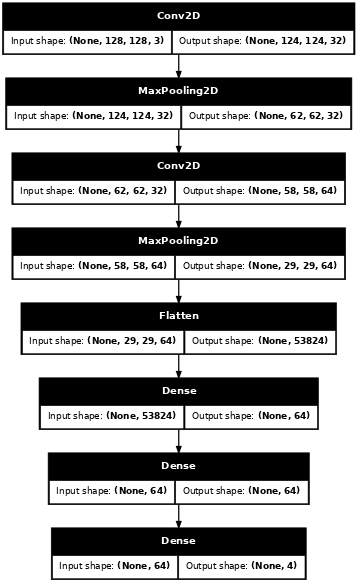

In [ ]:
# prompt: A diagram to explain the neural network
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})
ax.tick_params(axis='both', which='major', labelsize=14)  # Adjust labelsize as needed

plt.tight_layout()
plt.show()
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=False,dpi=45)


In [ ]:
history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size = 64,
                    validation_data=(X_val, y_val))

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.5173 - loss: 1.1367 - val_accuracy: 0.7039 - val_loss: 0.7008
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.8100 - loss: 0.4875 - val_accuracy: 0.8612 - val_loss: 0.3760
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.8852 - loss: 0.3001 - val_accuracy: 0.9018 - val_loss: 0.2757
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9436 - loss: 0.1761 - val_accuracy: 0.8996 - val_loss: 0.2776
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.9566 - loss: 0.1205 - val_accuracy: 0.9210 - val_loss: 0.2409
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.9720 - loss: 0.0811 - val_accuracy: 0.9317 - val_loss: 0.2299
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.9870 - loss: 0.0432 - val_accuracy: 0.9367 - val_loss: 0.2286
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.9894 - loss: 0.0310 - val_accuracy: 0.9409 - v

In [ ]:
y_pred = model.predict(X_test)
# Convert y_pred to class labels
y_pred_classes = np.argmax(y_pred, axis=1)
# Convert y_test to class labels
y_test_classes = np.argmax(y_test, axis=1)

accuracy = accuracy_score(y_test_classes, y_pred_classes)
print(accuracy)

44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 231ms/step
0.9380782918149466


Matriz de confusión:


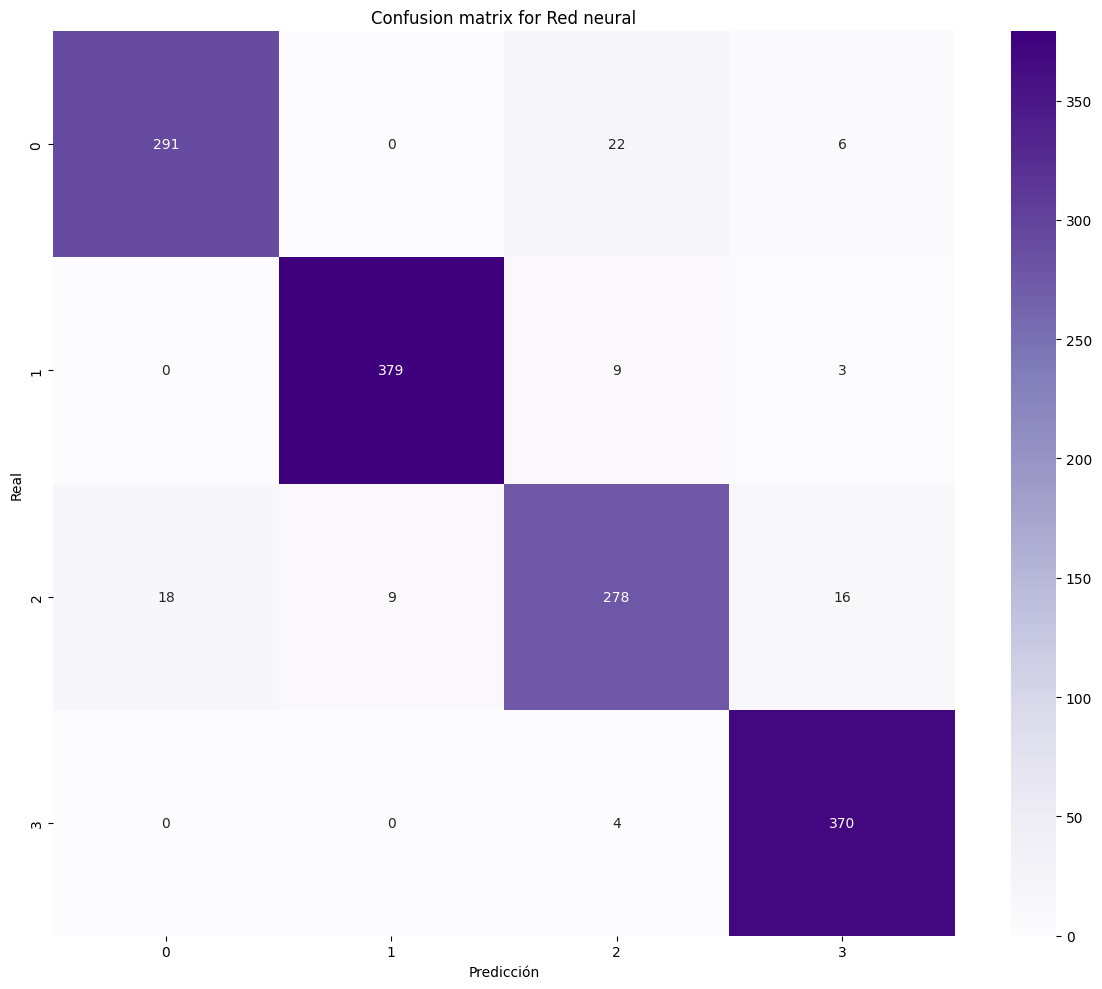

In [ ]:
confusion = confusion_matrix(y_test_classes, y_pred_classes)
print("Matriz de confusión:")

labels = ['0', '1', '2',"3"]

# Lista de matrices y títulos

fig, ax = plt.subplots(figsize=(12, 10))
# Graficar heatmaps en cada subplot
sns.heatmap(confusion, annot=True, fmt='d', cmap="Purples", xticklabels=labels, yticklabels=labels)
ax.set_title("Confusion matrix for Red neural")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(y_pred_classes,y_test_classes))

              precision    recall  f1-score   support

           0       0.91      0.94      0.93       309
           1       0.97      0.98      0.97       388
           2       0.87      0.89      0.88       313
           3       0.99      0.94      0.96       395

    accuracy                           0.94      1405
   macro avg       0.93      0.94      0.93      1405
weighted avg       0.94      0.94      0.94      1405



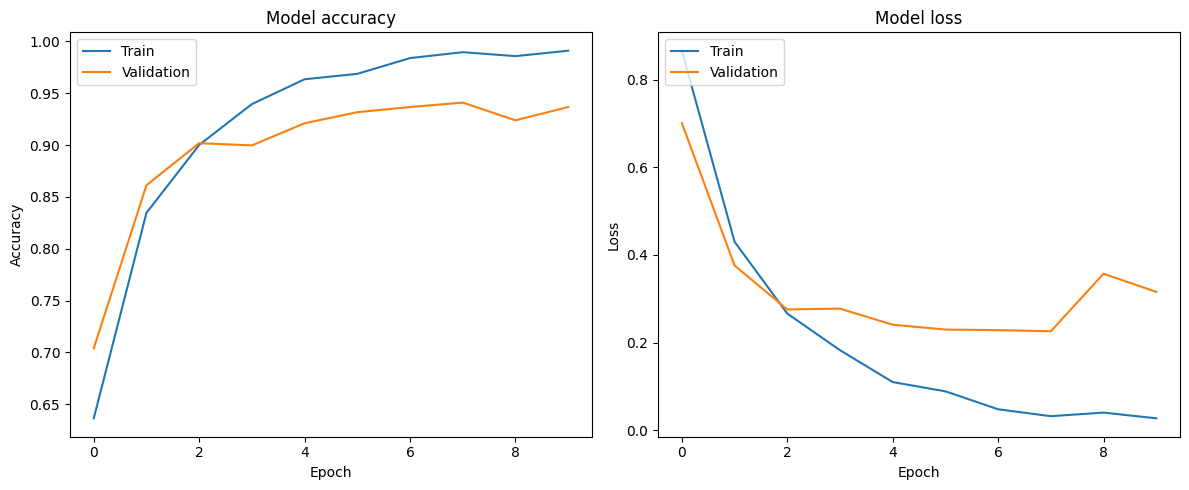

In [ ]:
def plot_model_results(history):
    """
    Plots the accuracy and loss curves of the model during training.

    Args:
        history: The training history object returned by model.fit.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot training & validation accuracy values
    axes[0].plot(history.history['accuracy'])
    axes[0].plot(history.history['val_accuracy'])
    axes[0].set_title('Model accuracy')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend(['Train', 'Validation'], loc='upper left')

    axes[1].plot(history.history['loss'])
    axes[1].plot(history.history['val_loss'])
    axes[1].set_title('Model loss')
    axes[1].set_ylabel('Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()
plot_model_results(history)

In [ ]:
import visualkeras
from PIL import ImageFont

In [ ]:
visualize_nn(model, output_file="my_network.png")

Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading

44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 226ms/step


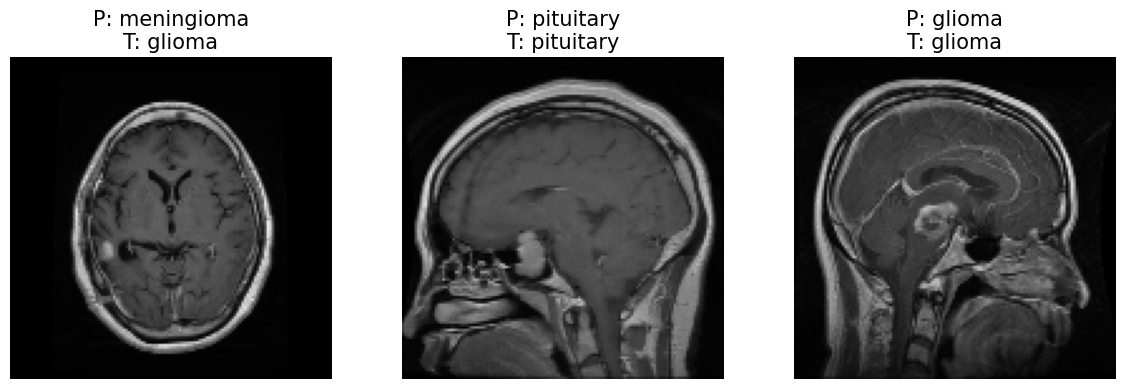

In [ ]:
def visualize_predictions(model, X_test, y_test, class_names, num_images=3):
    """
    Visualizes the predictions of the model on a subset of images,
    with one incorrect and two correct predictions.

    Args:
        model: The trained Keras model.
        X_test: The test data.
        y_test: The true labels for the test data.
        class_names: A list of class names corresponding to the model's output.
        num_images: The total number of images to visualize (default: 3).
    """

    # Get the model's predictions for all test data
    predictions = model.predict(X_test)
    predicted_labels = np.argmax(predictions, axis=1)
    true_labels = np.argmax(y_test, axis=1)

    # Find indices of correct and incorrect predictions
    correct_indices = np.where(predicted_labels == true_labels)[0]
    incorrect_indices = np.where(predicted_labels != true_labels)[0]

    # Select one incorrect prediction and two correct predictions
    selected_indices = [
        incorrect_indices[0],  # First incorrect prediction
        correct_indices[0],   # First correct prediction
        correct_indices[1],   # Second correct prediction
    ]

    # Get the corresponding images and labels
    images = X_test[selected_indices]
    labels = true_labels[selected_indices]

    # Create a figure and axes with adjusted size and layout
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))  # Adjusted for 3 over 1 layout

    # Plot each image with its prediction and true label
    for i, ax in enumerate(axes):
        ax.imshow(images[i])
        ax.set_title(f"P: {class_names[predicted_labels[selected_indices[i]]]}\nT: {class_names[labels[i]]}", fontsize=15)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(model, X_test, y_test, ["glioma", "healthy", "meningioma", "pituitary"], 3)